# Screening and Ranking Emerging Markets for M&A Targeting Using Macroeconomic Indicators
**ADS-505 Team Project    
Team 12: Jordyn Gonzales, Dana Neuman, James Shoenhair**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Problem Statement   
  
Corporate development and M&A teams routinely need to decide which emerging-market countries are currently the most attractive acquisition targets from a macroeconomic standpoint. Today that screening is largely manual: analysts lean on news coverage, prior deal experience, and country-by-country research, which is slow, inconsistent across analysts, and easy to bias toward markets that are already on the team's radar.   
  
**Goal:** build a transparent, repeatable model that screens and ranks emerging-market countries bt macroeconomic strength, using seven IMF World Economic Outlook (WEO) indicators:   
  
1. GDP growth (constant prices, % change)
2. GDP current prices (PPP, international \$)
3. GDP per capita (PPP, international \$)
4. GDP price deflator (index)
5. General government net debt (% of GDP)
6. General government net lending/borrowing (% of GDP)
7. Current account balance (% of GDP)  
  
The output is a ranked shortlist of countries plus visibility into which indicators drive each country's ranking, so the reasoning is transparent rather than a black box, and the analysis can be re-run each time the IMF releases a new WEO vintage. 

## Data Description  
  
**Source:** IMF World Economic Outlook (WEO) database, April 2026 vintage.  
  
**Raw Shape:** 1,288 rows x 22 columns   
  
- DATASET: IMF source dataset identifier 
- SERISE_CODE: IMF's internal code for this series
- OBS_MEASURE: Type of value the row holds
- COUNTRY: Country or entity name
- INDICATOR: Full-text name of the macroeconomic indicator being reported
- FREQUENCY: Reporting Frequency
- SCALE: Unit scale of the value columns
- 2017, 2018, . . . . , 2031: One column per year from 2017-2031. 2017-2025 are actuals/estimates, 2026-2031 are IMF projections. The value in each cell is that country's reading for the row's INDICATOR, in the unit given by SCALE

## Exploratory Data Analysis

In [2]:
# Load in dataset
df = pd.read_csv('ads505final.csv')
print(f"Shape:{df.shape}")
df.head()

Shape:(1288, 22)


,DATASET,SERIES_CODE,OBS_MEASURE,COUNTRY,INDICATOR,FREQUENCY,SCALE,2017,2018,2019,...,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031
0,IMF.RES:WEO(9.0.0),USA.NGDP_D.A,OBS_VALUE,United States,"Gross domestic product (GDP), Price deflator, ...",Annual,Units,100.000,102.291,103.979,...,118.023,122.390,125.428,128.986,132.681,135.595,137.821,140.271,142.849,145.428
1,IMF.RES:WEO(9.0.0),GBR.NGDP_D.A,OBS_VALUE,United Kingdom,"Gross domestic product (GDP), Price deflator, ...",Annual,Units,80.664,82.247,84.271,...,94.034,100.000,103.902,107.758,110.410,112.748,115.000,117.015,119.123,121.212
2,IMF.RES:WEO(9.0.0),G110.NGDP_RPCH.A,OBS_VALUE,Advanced Economies,"Gross domestic product (GDP), Constant prices,...",Annual,Units,2.609,2.312,1.859,...,3.055,1.702,1.839,1.935,1.777,1.700,1.747,1.613,1.537,1.513
3,IMF.RES:WEO(9.0.0),LKA.GGXCNL_NGDP.A,OBS_VALUE,Sri Lanka,"Net lending (+) / net borrowing (-), General g...",Annual,Units,-5.098,-4.956,-7.519,...,-10.223,-8.323,-5.426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,IMF.RES:WEO(9.0.0),GBR.BCA_NGDPD.A,OBS_VALUE,United Kingdom,"Current account balance (credit less debit), P...",Annual,Units,-3.379,-3.723,-2.479,...,-1.916,-3.570,-2.978,-3.126,-3.381,-3.144,-2.868,-2.565,-2.167,-2.218


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1288 entries, 0 to 1287
Data columns (total 22 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATASET      1288 non-null   object 
 1   SERIES_CODE  1288 non-null   object 
 2   OBS_MEASURE  1288 non-null   object 
 3   COUNTRY      1288 non-null   object 
 4   INDICATOR    1288 non-null   object 
 5   FREQUENCY    1288 non-null   object 
 6   SCALE        1288 non-null   object 
 7   2017         1286 non-null   float64
 8   2018         1287 non-null   float64
 9   2019         1288 non-null   float64
 10  2020         1282 non-null   float64
 11  2021         1282 non-null   float64
 12  2022         1282 non-null   float64
 13  2023         1282 non-null   float64
 14  2024         1282 non-null   float64
 15  2025         1269 non-null   float64
 16  2026         1254 non-null   float64
 17  2027         1247 non-null   float64
 18  2028         1242 non-null   float64
 19  2029  

In [4]:
df.nunique()

DATASET           1
SERIES_CODE    1288
OBS_MEASURE       1
COUNTRY         200
INDICATOR         7
FREQUENCY         1
SCALE             2
2017           1270
2018           1257
2019           1261
2020           1252
2021           1259
2022           1270
2023           1265
2024           1263
2025           1257
2026           1234
2027           1227
2028           1219
2029           1210
2030           1213
2031           1205
dtype: int64

In [5]:
# Clean up COUNTRY so that they are only an ISO-3 country/entity code
df['ISO_CODE'] = df['SERIES_CODE'].str.split('.').str[0]

# There are a couple aggregate groupings that we need to handle
aggregate_names = df.loc[df['ISO_CODE'].str.len() != 3, 'COUNTRY'].unique().tolist()
print('Non-country aggregates found in the data:')
for a in aggregate_names:
    print('-', a)

Non-country aggregates found in the data:
- Advanced Economies
- G7
- Other Advanced Economies (Advanced Economies excluding G7 and Euro Area countries)
- Euro Area (EA)


In [6]:
# We will drop the aggregates because we only want individual countries as candidate targets
data = df[~df['COUNTRY'].isin(aggregate_names)].copy()
print(f"Rows: {len(df)} -> {len(data)} after removing aggregates")
print(f"Unique countries: {data['COUNTRY'].nunique()}")

Rows: 1288 -> 1263 after removing aggregates
Unique countries: 196


In [7]:
data['INDICATOR'].unique()

array(['Gross domestic product (GDP), Price deflator, Index',
       'Net lending (+) / net borrowing (-), General government, Percent of GDP',
       'Current account balance (credit less debit), Percent of GDP',
       'Gross domestic product (GDP), Constant prices, Percent change',
       'Gross domestic product (GDP), Current prices, Purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021',
       'Gross domestic product (GDP), Per capita, purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021',
       'Net debt, General government, Percent of GDP'], dtype=object)

In [8]:
# Since INDICATOR values are long, we will map them to shorter, code-friendly names
INDICATOR_MAP  = {
    'Gross domestic product (GDP), Price deflator, Index': 'gdp_deflator_idx',
    'Net lending (+) / net borrowing (-), General government, Percent of GDP': 'net_lending_pct_gdp',
    'Current account balance (credit less debit), Percent of GDP': 'current_account_pct_gdp',
    'Gross domestic product (GDP), Constant prices, Percent change': 'gdp_growth_pct',
    'Gross domestic product (GDP), Current prices, Purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021': 'gdp_ppp_bn',
    'Gross domestic product (GDP), Per capita, purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021': 'gdp_per_capita_ppp',
    'Net debt, General government, Percent of GDP':'net_debt_pct_gdp'}
data['indicator'] = data['INDICATOR'].map(INDICATOR_MAP)

In [9]:
# reshape from dataset from wide to long (make it one row per country-indicator-year)
YEAR_COLS = [str(y) for y in range(2017, 2032)]
df_long = data.melt( id_vars=['COUNTRY', 'ISO_CODE', 'indicator'], 
                    value_vars = YEAR_COLS, var_name='year', value_name='value')
df_long['year'] = df_long['year'].astype(int)

In [10]:
all_countries = sorted(data['COUNTRY'].unique())
all_indicators = sorted(INDICATOR_MAP.values())
full_index = pd.MultiIndex.from_product(
    [all_countries, all_indicators, range(2017, 2032)],
    names=['COUNTRY', 'indicator', 'year']
)
df_long = (df_long.set_index(['COUNTRY', 'indicator', 'year'])
                    .reindex(full_index)
                    .reset_index())
print(f"Complete grid: {len(df_long)} rows "
      f"({len(all_countries)} countries x {len(all_indicators)} indicators x 15 years)")
df_long.head()

Complete grid: 20580 rows (196 countries x 7 indicators x 15 years)


,COUNTRY,indicator,year,ISO_CODE,value
0,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2017,AFG,7.576
1,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2018,AFG,12.143
2,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2019,AFG,11.705
3,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2020,AFG,13.974
4,"Afghanistan, Islamic Republic of",current_account_pct_gdp,2021,AFG,-0.056


A country that doesn't report a given indicator at all has no row for that (country, indicator) pair, rather than a row full of `NaN`. By only looking at the rows that exist, we will systematically undercount missingness. To fix this we re-index onto the complete grid of every contry x every indicator x every year. Now any country that wasn't in the raw original file becomes a `NaN` that we can measure

In [11]:
# to learn more about the type of missingness so we know how to handle it later
missing1 = df_long.groupby('indicator')['value'].apply(lambda s: s.isna().mean()*100).round(1)
missing2 = df_long.groupby('indicator').apply(lambda g: g.groupby('COUNTRY')['value'].apply(lambda s: s.isna().all()).sum())
missing_summary = pd.DataFrame({'% of country-years missing': missing1, 'countries with no data at all': missing2
                               }).sort_values('% of country-years missing', ascending = False)
missing_summary

,% of country-years missing,countries with no data at all
indicator,,
net_debt_pct_gdp,55.7,108
current_account_pct_gdp,2.2,1
net_lending_pct_gdp,1.9,0
gdp_deflator_idx,1.6,0
gdp_growth_pct,1.6,0
gdp_per_capita_ppp,1.6,0
gdp_ppp_bn,1.6,0


This table shows that six of the seven indicators only have about 1-2% missing values, which are likely from small or newly-independent countries. The only indicator with a substantial amount of missing values is `net_debt_pct_gdp`. This is a structural gap from smaller/lower-income economies that don't publish the underlying government balance-sheet data. (missing values will be handled in pre-processing).

To look at the distributions and outliers, we will use 2025 for a cross-sectional look. We chose 2025 because it sits at the boundary between atcual/estimated and projected data. Using this single-year snapshot will give us a fixed, representative view for understanding each indicators shape, outliers, and relationships.

In [12]:
snapshot2025 = (df_long[df_long['year'] == 2025].pivot(index='COUNTRY', columns='indicator', values='value'))
snapshot2025.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
indicator,,,,,,,,
current_account_pct_gdp,192.0,-1.700000e+00,1.060000e+01,-53.3,-5.6,-1.9,3.2,3.570000e+01
gdp_deflator_idx,193.0,4.414270e+13,6.132500e+14,83.8,120.5,137.0,191.6,8.519541e+15
gdp_growth_pct,192.0,3.700000e+00,4.200000e+00,-6.4,1.8,3.1,4.9,4.610000e+01
gdp_per_capita_ppp,193.0,3.285340e+04,3.391410e+04,994.2,7985.2,20777.5,49491.7,1.924199e+05
gdp_ppp_bn,193.0,1.087700e+03,4.011800e+03,0.1,34.9,123.4,626.7,4.124200e+04
net_debt_pct_gdp,88.0,4.600000e+01,3.650000e+01,-160.2,27.6,44.3,63.5,1.365000e+02
net_lending_pct_gdp,193.0,-2.900000e+00,6.400000e+00,-48.0,-4.8,-2.8,-1.0,3.160000e+01


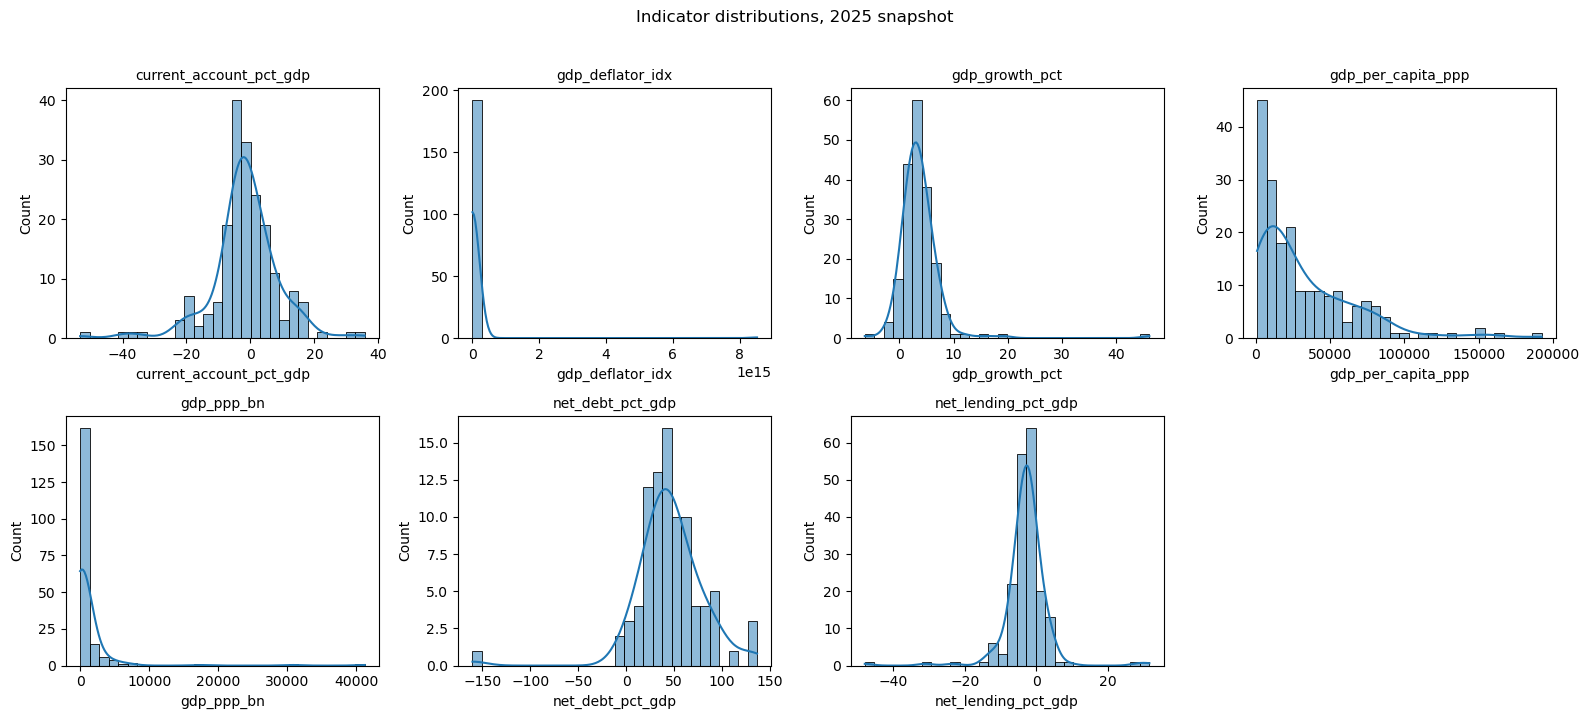

In [13]:
fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, col in zip(axes.flat, snapshot2025.columns):
    sns.histplot(snapshot2025[col].dropna(), ax=ax, kde=True, bins=30)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.suptitle('Indicator distributions, 2025 snapshot', y=1.02)
plt.tight_layout()
plt.show()

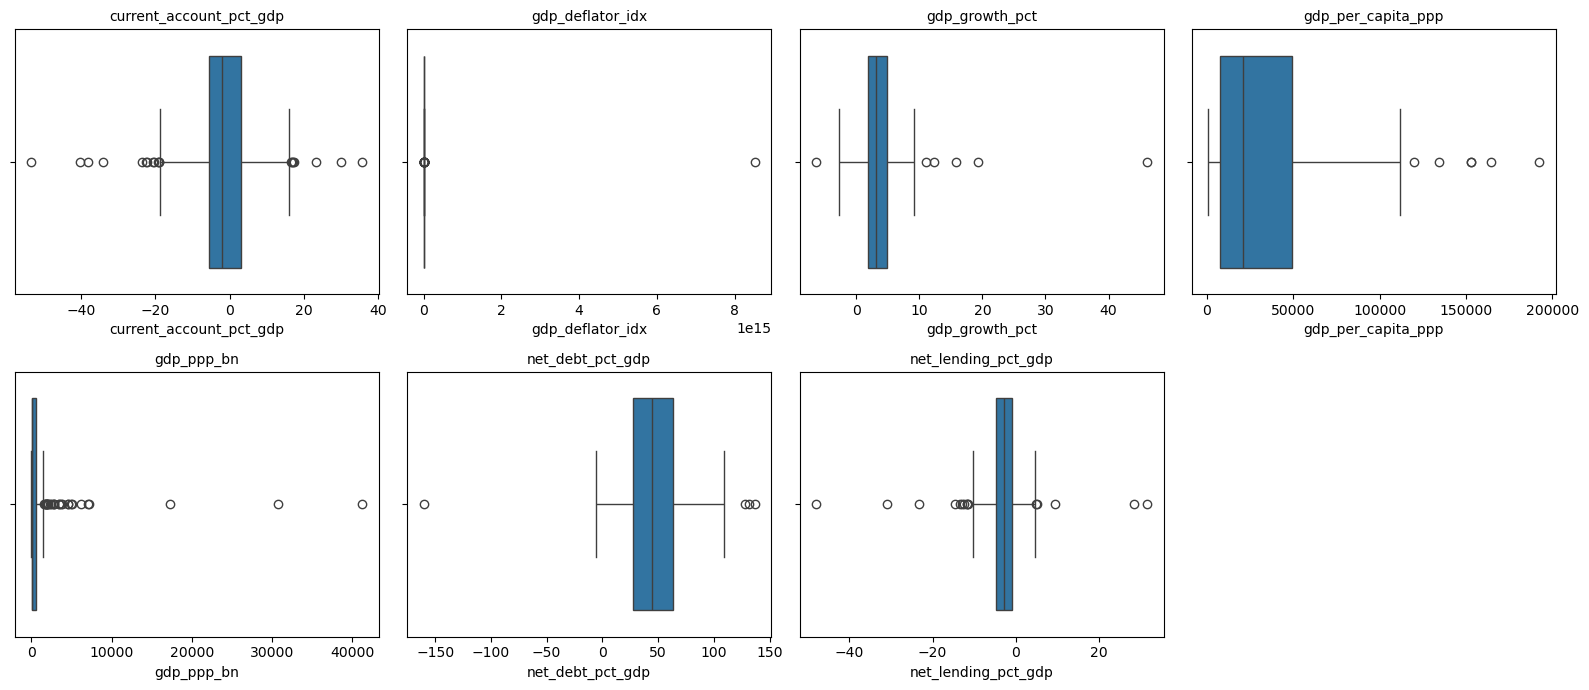

In [14]:
fig, axes = plt.subplots(2,4, figsize = (16,7))
for ax, col in zip(axes.flat, snapshot2025.columns):
    sns.boxplot(x=snapshot2025[col].dropna(), ax=ax)
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [15]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25,.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lo) | (s > hi)].sort_values(ascending=False)
print('Top outliers, GDP price deflator index (2025):')
print(iqr_outliers(snapshot2025['gdp_deflator_idx']).head(5))

Top outliers, GDP price deflator index (2025):
COUNTRY
Venezuela, República Bolivariana de    8.519541e+15
Sudan                                  9.416680e+05
South Sudan, Republic of               1.499393e+05
Argentina                              1.146898e+05
Tajikistan, Republic of                3.756713e+04
Name: gdp_deflator_idx, dtype: float64


These outlier countries are from a direct reflection of real hyperinflation, not a data-entry error. Because a price-level index is inherently multiplicative/exponential once hyperinflation sets in, this variable needs a log transform instead of just capping it. If we were to cap it, the transformed distribution would be unusuable since almost the entire non-outlier population would be squeezed into a sliver of the scale. The other 6 indicators have a small number of legitimate extreme outliers. 

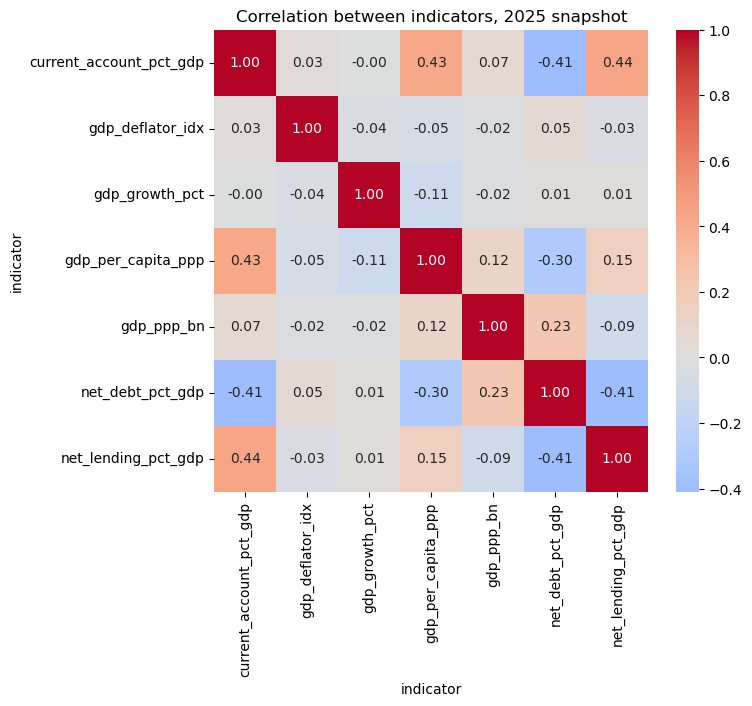

In [16]:
# check correlation between indicators
corr = snapshot2025.corr()
fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap ='coolwarm', center=0, ax=ax)
ax.set_title('Correlation between indicators, 2025 snapshot')
plt.show()

Correlations among the indicators are generally weak to moderate. The strongest relationships are intuititive (like net lending/borrowing correlates positively with the current account balance).

## Data Pre-processing

In [17]:
# Build a current and outlook level since a single snapshot year is noisy
CURRENT_YEARS = [2023, 2024, 2025]
OUTLOOK_YEARS = [2026, 2027, 2028]

current = (df_long[df_long['year'].isin(CURRENT_YEARS)].groupby(['COUNTRY', 'indicator'])['value'].mean().unstack())
outlook = (df_long[df_long['year'].isin(OUTLOOK_YEARS)].groupby(['COUNTRY', 'indicator'])['value'].mean().unstack())

current.columns = [f'{c}_current' for c in current.columns]
outlook.columns = [f'{c}_outlook' for c in outlook.columns]

features = pd.concat([current, outlook], axis=1)
print(features.shape)
features.isna().sum()

(196, 14)


current_account_pct_gdp_current      2
gdp_deflator_idx_current             1
gdp_growth_pct_current               1
gdp_per_capita_ppp_current           1
gdp_ppp_bn_current                   1
net_debt_pct_gdp_current           108
net_lending_pct_gdp_current          1
current_account_pct_gdp_outlook      6
gdp_deflator_idx_outlook             5
gdp_growth_pct_outlook               5
gdp_per_capita_ppp_outlook           5
gdp_ppp_bn_outlook                   5
net_debt_pct_gdp_outlook           110
net_lending_pct_gdp_outlook          7
dtype: int64

Averaging three years mostly took care of the identical 1-2% gaps from the EDA section, they are now down to a handful of countries per column. 

In [18]:
# missing values
for col in ['net_debt_pct_gdp_current', 'net_debt_pct_gdp_outlook']:
    flag = col + '_imputed'
    features[flag] = features[col].isna()
    features[col] = features[col].fillna(features[col].median())
    print(f'{col}: imputed {features[flag].sum()} countries with the cross-sectional median')
    
core_cols = [c for c in features.columns if not c.endswith('_imputed')]
before = len(features)
features = features.dropna(subset=core_cols)
print(f'\nDropped {before - len(features)} countries with unrecoverable gaps in other indicators')
print(f'Final country count: {len(features)}')
      

net_debt_pct_gdp_current: imputed 108 countries with the cross-sectional median
net_debt_pct_gdp_outlook: imputed 110 countries with the cross-sectional median

Dropped 8 countries with unrecoverable gaps in other indicators
Final country count: 188


To deal with `net_debt_pct_gdp` missing values, we impute the cross-sectional median and add a boolean flag column so any downstream model can see which countries' debt figure is imputed rather than reported. This will keep every country in the ranking while being transparent about the limitatio, rather than quietly treating an imputed values as if it were real IMF data. For the small remaining number of countries missing of the other six indicators, there's no reliable substitute value available in this dataset, so those few rows were fropped. 

In [19]:
# outliers
def winsorize(s, lower=0.01, upper=0.99):
    lo, hi = s.quantile([lower, upper])
    return s.clip(lo, hi)

for col in ['gdp_deflator_idx_current', 'gdp_deflator_idx_outlook']:
    features[col + '_log'] = np.log10(features[col])

winsor_cols = [c for c in core_cols if 'deflator' not in c]
for col in winsor_cols:
    features[col + '_wz'] = winsorize(features[col])

print("Before/after example -- gdp_deflator_idx_current vs its log:")
print(features[['gdp_deflator_idx_current']].describe().T.round(1))
print(features[['gdp_deflator_idx_current_log']].describe().T.round(2))

Before/after example -- gdp_deflator_idx_current vs its log:
                          count    mean      std   min    25%    50%    75%  \
gdp_deflator_idx_current  188.0  4070.8  39008.3  88.2  118.0  131.3  182.0   

                               max  
gdp_deflator_idx_current  521349.8  
                              count  mean   std   min   25%   50%   75%   max
gdp_deflator_idx_current_log  188.0  2.27  0.48  1.95  2.07  2.12  2.26  5.72


To deal with the outliers we first log transformed `gdp_deflator_idx`. For the other six indicators we winsorized at the 1st/99th percentile (capped, not removed), so a handful of extreme-but-real economies don't dominate a distance and every country stays in the dataset

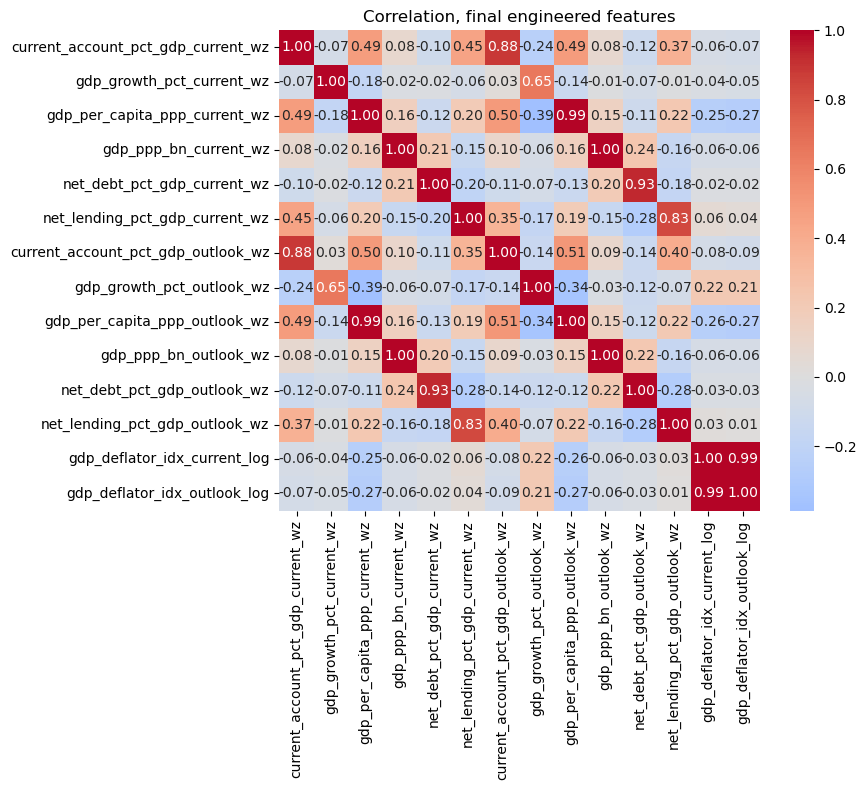

In [20]:
# check the engineered/treated features preserve the same structure from the raw 2025 snapshot
final_model_cols = [c for c in features.columns if c.endswith('_wz')] + \
                    [c for c in features.columns if c.endswith('_log')]
corr_final = features[final_model_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(corr_final, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            xticklabels=True, yticklabels=True)
ax.set_title('Correlation, final engineered features')
plt.tight_layout()
plt.show()